In [1]:
# Backpropagation Under the Microscope

### An Experimental Study of Gradient Flow, Parameter Updates, and Learning Dynamics in Neural Networks

# This project investigates how neural networks learn through backpropagation.

# The experiments will examine:
# - how gradients are calculated,
# - how parameters change during training,
# - how learning rate affects optimization,
# - how initialization affects learning trajectories,
# - how activation functions affect gradient propagation,
# - how network depth affects gradients,
# - and how different optimization algorithms change the learning process.

In [2]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # tells OpenMP "it's fine, let both copies exist"

import torch
import numpy as np
import matplotlib.pyplot as plt

In [3]:
def sigmoid(z):
    return 1/(1+np.exp(-z))
def sigmoid_derivative(z):
    s=sigmoid(z)
    return s*(1-s)

In [4]:
values=np.array([-5,-1,-0,1,5])
print("z values: ")
print(values)
print("\nsigmoid(z):")
print(sigmoid(values))
print("\nsigmoid'(z):")
print(sigmoid_derivative(values))

z values: 
[-5 -1  0  1  5]

sigmoid(z):
[0.00669285 0.26894142 0.5        0.73105858 0.99330715]

sigmoid'(z):
[0.00664806 0.19661193 0.25       0.19661193 0.00664806]


In [5]:
x=np.array([[1],[0]])
print(x)
print(x.shape)

[[1]
 [0]]
(2, 1)


In [6]:
w1=np.array([
    [0.5,0.2],
    [-0.3,0.8]
])
b1=np.array([
    [0.1],
    [0.2]
])
print("w1: ",w1)
print("Shape of w1: ",w1.shape)
print("b1: ",b1)
print("Shape of b1: ", b1.shape)

w1:  [[ 0.5  0.2]
 [-0.3  0.8]]
Shape of w1:  (2, 2)
b1:  [[0.1]
 [0.2]]
Shape of b1:  (2, 1)


In [7]:
# computing the weighted sum
z1=w1@x+b1
print("z1 :")
print(z1)
print(z1.shape)


z1 :
[[ 0.6]
 [-0.1]]
(2, 1)


In [8]:
# computing our first activation function
a1=sigmoid(z1)
print("a1 :")
print(a1)

a1 :
[[0.64565631]
 [0.47502081]]


In [9]:
w2=np.array([
    [0.7,-0.4]
])
print("w2 :")
print(w2)
print(w2.shape)
b2=np.array([
    [0.1]
])
print("b2 :")
print(b2)
print(b2.shape)

w2 :
[[ 0.7 -0.4]]
(1, 2)
b2 :
[[0.1]]
(1, 1)


In [10]:
z2 = w2@ a1 + b2

print("z2:")
print(z2)

z2:
[[0.36195109]]


In [11]:
y_hat=sigmoid(z2)
print("prediction:")
print(y_hat)

prediction:
[[0.58951266]]


In [12]:
# loss calculation using MSE
import numpy as np
y=np.array([1])
print("Actual target:",y)

loss=0.5*(y-y_hat)**2
print("Loss ;",loss)

Actual target: [1]
Loss ; [[0.08424993]]


In [13]:
# backpropagation
import torch
import numpy as np
x = torch.tensor([
    [1.0],
    [0.0]
])

print(x)
print("Shape:", x.shape)

tensor([[1.],
        [0.]])
Shape: torch.Size([2, 1])


In [14]:
W1 = torch.tensor([
    [0.5, 0.2],
    [-0.3, 0.8]
], requires_grad=True)
print(W1)
print("Shape:", W1.shape)

b1 = torch.tensor([
    [0.1],
    [0.2]
], requires_grad=True)
print(b1)
print("Shape:", b1.shape)

W2 = torch.tensor([
    [0.7, -0.4]
], requires_grad=True)
print(W2)
print("Shape:", W2.shape)

b2 = torch.tensor([
    [0.1]
], requires_grad=True)
print(b2)
print("Shape:", b2.shape)

# requires_grad=True means requires gradient

tensor([[ 0.5000,  0.2000],
        [-0.3000,  0.8000]], requires_grad=True)
Shape: torch.Size([2, 2])
tensor([[0.1000],
        [0.2000]], requires_grad=True)
Shape: torch.Size([2, 1])
tensor([[ 0.7000, -0.4000]], requires_grad=True)
Shape: torch.Size([1, 2])
tensor([[0.1000]], requires_grad=True)
Shape: torch.Size([1, 1])


In [15]:
z1 = W1 @ x + b1
print("z1:")
print(z1)

z1:
tensor([[ 0.6000],
        [-0.1000]], grad_fn=<AddBackward0>)


In [16]:
a1 = torch.sigmoid(z1)
# .sigmoid() to calculate sigmoid of z1
print("a1:")
print(a1)

a1:
tensor([[0.6457],
        [0.4750]], grad_fn=<SigmoidBackward0>)


In [17]:
# the above cell was forward prop.
# output layer is given as:
z2 = W2 @ a1 + b2
print("z2:")
print(z2)

z2:
tensor([[0.3620]], grad_fn=<AddBackward0>)


In [18]:
# predicted output:
y_hat = torch.sigmoid(z2)
print("Prediction:")
print(y_hat)

Prediction:
tensor([[0.5895]], grad_fn=<SigmoidBackward0>)


In [19]:
# calculating loss:

In [20]:
y = torch.tensor([
    [1.0]
])
print(y)
print("Shape:", y.shape)
# this is our actual output

tensor([[1.]])
Shape: torch.Size([1, 1])


In [21]:
# loss using mse
loss = 0.5 * (y - y_hat) ** 2
print("Loss:",loss)

Loss: tensor([[0.0842]], grad_fn=<MulBackward0>)


In [22]:
# backpropagation
loss.backward()

print("Gradient of W2:")
print(W2.grad)

print("\nGradient of b2:")
print(b2.grad)

print("\nGradient of W1:")
print(W1.grad)

print("\nGradient of b1:")
print(b1.grad)

Gradient of W2:
tensor([[-0.0641, -0.0472]])

Gradient of b2:
tensor([[-0.0993]])

Gradient of W1:
tensor([[-0.0159, -0.0000],
        [ 0.0099,  0.0000]])

Gradient of b1:
tensor([[-0.0159],
        [ 0.0099]])


In [23]:
print("dL/dy_hat:")
print(y_hat - y)

dL/dy_hat:
tensor([[-0.4105]], grad_fn=<SubBackward0>)


In [24]:
# optimising using stochastic gradient descent/SGD
optimizer = torch.optim.SGD(
    [W1, b1, W2, b2],
    lr=0.1
)
# lr=learning rate=0.1
optimizer.step()
# uses gradients to update parameters

optimizer.zero_grad()
# to clear the old gradients so that operations on new gradients can be done

In [25]:
print("W1:")
print(W1)

print("\nW2:")
print(W2)

W1:
tensor([[ 0.5016,  0.2000],
        [-0.3010,  0.8000]], requires_grad=True)

W2:
tensor([[ 0.7064, -0.3953]], requires_grad=True)


In [26]:
learning_rate = 0.1

optimizer = torch.optim.SGD(
    [W1, b1, W2, b2],
    lr=learning_rate
)

print(" updated W1:")
print(W1)

print("\n updated W2:")
print(W2)

 updated W1:
tensor([[ 0.5016,  0.2000],
        [-0.3010,  0.8000]], requires_grad=True)

 updated W2:
tensor([[ 0.7064, -0.3953]], requires_grad=True)


In [27]:
optimizer.zero_grad()

In [28]:
# RUNNING EPOCHS

# .item() is used to convert matrix having single values into a normal integer 
# that ends our experiment
# we'll record the result in an array
loss_history=[]

epochs=100
for epoch in range(epochs):
    optimizer.zero_grad()
    
    z1=W1@x+b1
    a1=torch.sigmoid(z1)
    z2=W2@a1+b2
    y_hat=torch.sigmoid(z2)

    loss=0.5*(y_hat-y)**2

    loss.backward()

    optimizer.step()
    loss_history.append(loss.item())
    if epoch % 10 == 0:
        print(
            f"Epoch {epoch}, "
            f"Loss: {loss.item():.6f}, "
            f"Prediction: {y_hat.item():.6f}"
        )

Epoch 0, Loss: 0.082570, Prediction: 0.593626
Epoch 10, Loss: 0.067970, Prediction: 0.631300
Epoch 20, Loss: 0.056714, Prediction: 0.663209
Epoch 30, Loss: 0.047984, Prediction: 0.690212
Epoch 40, Loss: 0.041142, Prediction: 0.713148
Epoch 50, Loss: 0.035711, Prediction: 0.732752
Epoch 60, Loss: 0.031342, Prediction: 0.749633
Epoch 70, Loss: 0.027782, Prediction: 0.764281
Epoch 80, Loss: 0.024844, Prediction: 0.777090
Epoch 90, Loss: 0.022393, Prediction: 0.788374


In [29]:
# we'll run the further experments using a 'train()' function which will train the data according to our experiments
# we'll change the learning rates, initialisation, activation function, etc to understand how much a neural network changes if we change the small details

In [30]:
def train(W1, b1, W2, b2, x, y, optimizer, epochs):
    loss_history = []
    prediction_history = []

    for epoch in range(epochs):
        optimizer.zero_grad()
        
        z1 = W1 @ x + b1
        a1 = torch.sigmoid(z1)
        z2 = W2 @ a1 + b2
        y_hat = torch.sigmoid(z2)

        loss = 0.5 * (y - y_hat) ** 2
        
        loss.backward()
        
        optimizer.step()

        loss_history.append(loss.item())
        prediction_history.append(y_hat.item())

    return loss_history, prediction_history
    
def reset_network():
    W1 = torch.tensor([
        [0.5, 0.2],
        [-0.3, 0.8]
    ], requires_grad=True)

    b1 = torch.tensor([
        [0.1],
        [0.2]
    ], requires_grad=True)

    W2 = torch.tensor([
        [0.7, -0.4]
    ], requires_grad=True)

    b2 = torch.tensor([
        [0.1]
    ], requires_grad=True)

    optimizer = torch.optim.SGD(
        [W1, b1, W2, b2],
        lr=0.1
    )
    return W1, b1, W2, b2, optimizer

In [31]:
# reset_network() will be done before every experiment so that we start with the same old weights again
reset_network()

(tensor([[ 0.5000,  0.2000],
         [-0.3000,  0.8000]], requires_grad=True),
 tensor([[0.1000],
         [0.2000]], requires_grad=True),
 tensor([[ 0.7000, -0.4000]], requires_grad=True),
 tensor([[0.1000]], requires_grad=True),
 SGD (
 Parameter Group 0
     dampening: 0
     differentiable: False
     foreach: None
     fused: None
     lr: 0.1
     maximize: False
     momentum: 0
     nesterov: False
     weight_decay: 0
 ))

In [32]:
# input and target
x = torch.tensor([
    [1.0],
    [0.0]
])

y = torch.tensor([
    [1.0]
])

# creating the optimiser (using stochastic gradient descent
optimizer = torch.optim.SGD(
    [W1, b1, W2, b2],
    lr=0.1
)

# training the model
loss_history, prediction_history = train( W1, b1, W2, b2,x, y,optimizer,epochs=100)

# results
print("Initial loss:", loss_history[0])
print("Final loss:", loss_history[-1])

print("\nInitial prediction:", prediction_history[0])
print("Final prediction:", prediction_history[-1])

Initial loss: 0.020324839279055595
Final loss: 0.010041847825050354

Initial prediction: 0.7983823418617249
Final prediction: 0.8582830429077148


In [33]:
print(len(loss_history))
print(len(prediction_history))

100
100


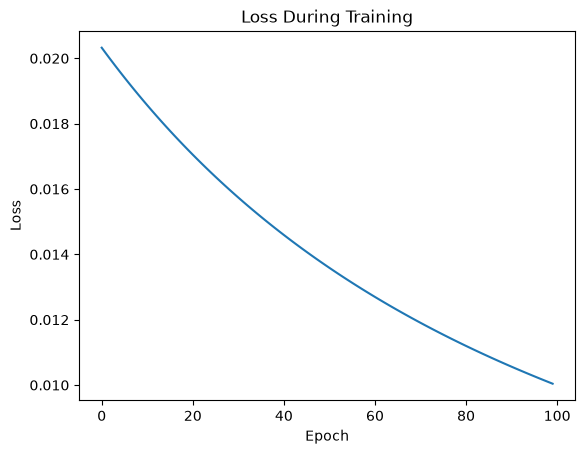

In [34]:
# plotting our findings
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss During Training")
plt.show()

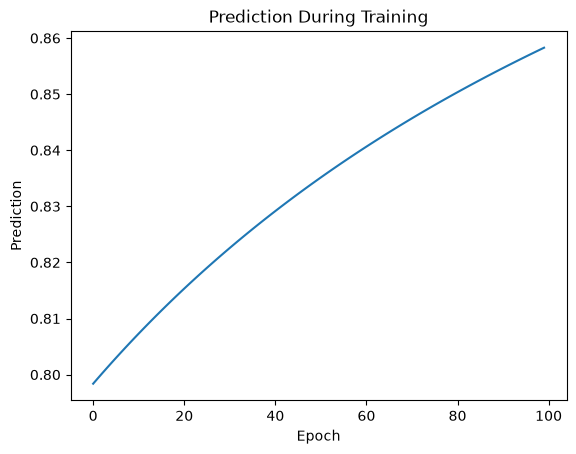

In [35]:
plt.plot(prediction_history)
plt.xlabel("Epoch")
plt.ylabel("Prediction")
plt.title("Prediction During Training")
plt.show()

In [36]:
def train(W1, b1, W2, b2, x, y, optimizer, epochs):

    loss_history = []
    prediction_history = []
    gradient_history = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        z1 = W1 @ x + b1
        a1 = torch.sigmoid(z1)
        z2 = W2 @ a1 + b2
        y_hat = torch.sigmoid(z2)

        loss = 0.5 * (y - y_hat) ** 2
        loss.backward()
        
        gradient_history.append({
            "W1": torch.norm(W1.grad).item(),
            "W2": torch.norm(W2.grad).item()
        })

        optimizer.step()
        loss_history.append(loss.item())
        prediction_history.append(y_hat.item())

    return loss_history, prediction_history, gradient_history

In [37]:
loss_history, prediction_history, gradient_history = train(W1, b1, W2, b2,x, y,optimizer,epochs=100)

# results
print("First gradient:")
print(gradient_history[0])
print("\nLast gradient:")
print(gradient_history[-1])

First gradient:
{'W1': 0.004342944826930761, 'W2': 0.014584655873477459}

Last gradient:
{'W1': 0.002995842369273305, 'W2': 0.009756932966411114}


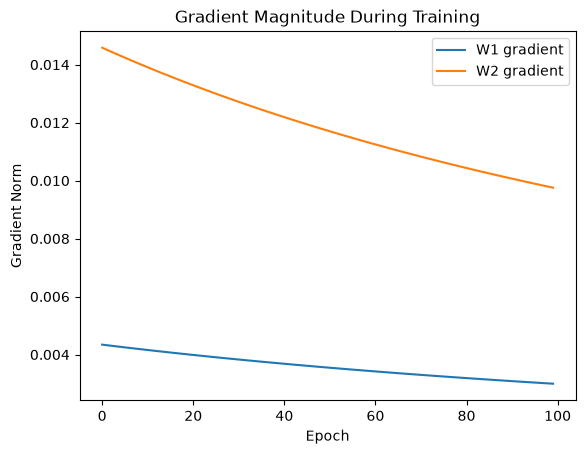

In [38]:
# plotting gradeint dynamics
W1_gradients = [item["W1"] for item in gradient_history]
W2_gradients = [item["W2"] for item in gradient_history]

plt.plot(W1_gradients, label="W1 gradient")
plt.plot(W2_gradients, label="W2 gradient")

plt.xlabel("Epoch")
plt.ylabel("Gradient Norm")
plt.title("Gradient Magnitude During Training")
plt.legend()
plt.show()

In [39]:

# updated train() function
def train(W1, b1, W2, b2, x, y, optimizer, epochs):

    loss_history = []
    prediction_history = []
    gradient_history = []
    update_history = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        z1 = W1 @ x + b1
        a1 = torch.sigmoid(z1)
        z2 = W2 @ a1 + b2
        y_hat = torch.sigmoid(z2)
        loss = 0.5 * (y - y_hat) ** 2
        
        loss.backward()

        gradient_history.append({
            "W1": torch.norm(W1.grad).item(),
            "W2": torch.norm(W2.grad).item()
        })

        W1_before = W1.detach().clone()
        W2_before = W2.detach().clone()

        optimizer.step()
        
        W1_update = torch.norm(W1.detach() - W1_before).item()
        W2_update = torch.norm(W2.detach() - W2_before).item()

        update_history.append({
            "W1": W1_update,
            "W2": W2_update
        })
        loss_history.append(loss.item())
        prediction_history.append(y_hat.item())

    return (loss_history,
        prediction_history,
        gradient_history,
        update_history)
# .clone() to create copies


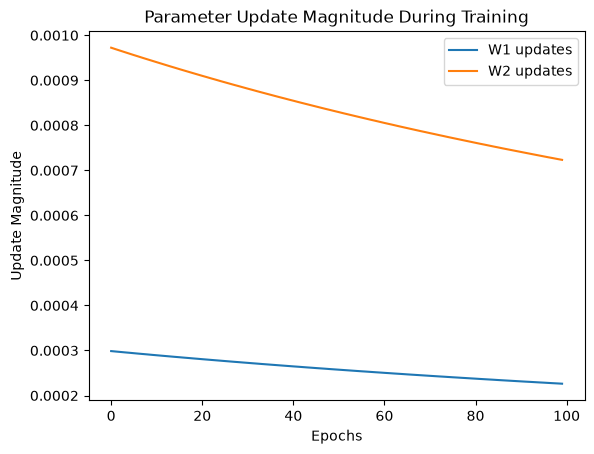

In [40]:
loss_history, prediction_history, gradient_history, update_history = train(W1, b1, W2, b2,x, y,optimizer,epochs=100)
W1_updates = [item["W1"] for item in update_history]
W2_updates = [item["W2"] for item in update_history]

# plot it
plt.plot(W1_updates,label="W1 updates")
plt.plot(W2_updates,label="W2 updates")
plt.xlabel('Epochs')
plt.ylabel("Update Magnitude")
plt.title("Parameter Update Magnitude During Training")
plt.legend()
plt.show()

In [41]:
W1, b1, W2, b2, optimizer = reset_network()

optimizer.zero_grad()
# Gradients are stored inside the tensors:
z1 = W1 @ x + b1
a1 = torch.sigmoid(z1)

z2 = W2 @ a1 + b2
y_hat = torch.sigmoid(z2)

loss = 0.5 * (y - y_hat) ** 2

loss.backward()

analytical_gradient = W2.grad[0, 0].item()

print("Analytical gradient:", analytical_gradient)

# PyTorch accumulates gradients by default (W1.grad, W2.grad,b1.grad, b2.grad)

Analytical gradient: -0.06413485109806061


In [42]:
# W2[0, 0] testing with weight [0,0]

epsilon = 1e-5
original_value = W2[0, 0].item()

with torch.no_grad():
    W2[0, 0] = original_value + epsilon

# to calculate loss_plus
with torch.no_grad():

    W2[0, 0] = original_value + epsilon
    # manually changing the the weight parameter
    
    z1 = W1 @ x + b1
    a1 = torch.sigmoid(z1)

    z2 = W2 @ a1 + b2
    y_hat = torch.sigmoid(z2)

    loss_plus = 0.5 * (y - y_hat) ** 2

# to calculate loss_minus
with torch.no_grad():

    W2[0, 0] = original_value - epsilon

    z1 = W1 @ x + b1
    a1 = torch.sigmoid(z1)

    z2 = W2 @ a1 + b2
    y_hat = torch.sigmoid(z2)

    loss_minus = 0.5 * (y - y_hat) ** 2

In [43]:
numerical_gradient = ((loss_plus.item() - loss_minus.item())/ (2 * epsilon))
print("Numerical gradient:", numerical_gradient)

Numerical gradient: -0.0648200511932373


In [44]:
with torch.no_grad():
    W2[0, 0] = original_value

print("Analytical gradient:", analytical_gradient)
print("Numerical gradient:", numerical_gradient)

difference = abs(analytical_gradient - numerical_gradient)
print("Difference b/w analytical and numerical gradient:", difference)

Analytical gradient: -0.06413485109806061
Numerical gradient: -0.0648200511932373
Difference b/w analytical and numerical gradient: 0.0006852000951766968


In [45]:
def train(W1, b1, W2, b2, x, y, optimizer, epochs):
    loss_history = []
    prediction_history = []

    for epoch in range(epochs):
        optimizer.zero_grad()
        
        z1 = W1 @ x + b1
        a1 = torch.sigmoid(z1)
        z2 = W2 @ a1 + b2
        y_hat = torch.sigmoid(z2)

        loss = 0.5 * (y - y_hat) ** 2
        
        loss.backward()
        
        optimizer.step()

        loss_history.append(loss.item())
        prediction_history.append(y_hat.item())

    return loss_history, prediction_history

In [46]:
learning_rates = [0.001, 0.01, 0.1, 1.0]
def reset_network():

    W1 = torch.tensor([
        [0.5, 0.2],
        [-0.3, 0.8]
    ], requires_grad=True)

    b1 = torch.tensor([
        [0.1],
        [0.2]
    ], requires_grad=True)

    W2 = torch.tensor([
        [0.7, -0.4]
    ], requires_grad=True)

    b2 = torch.tensor([
        [0.1]
    ], requires_grad=True)

    return W1, b1, W2, b2
    
W1, b1, W2, b2 = reset_network()
optimizer = torch.optim.SGD([W1, b1, W2, b2],lr=0.1)
loss_history, prediction_history = train(W1, b1, W2, b2,x, y,optimizer,epochs=100)

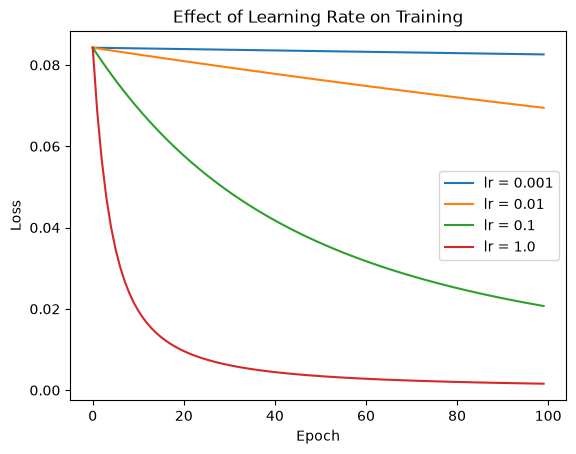

In [47]:
# experiment 2 : changing learning rates

learning_rates = [0.001, 0.01, 0.1, 1.0]
results={}
for lr in learning_rates:
    W1, b1, W2, b2 = reset_network()
    optimizer=torch.optim.SGD([W1,b1,W2,b2],lr=lr)
    loss_history, prediction_history = train(W1, b1, W2, b2,x, y,optimizer,epochs=100)
    results[lr]=loss_history

# plotting our findings
for lr in learning_rates:
    plt.plot(results[lr],label=f"lr = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Learning Rate on Training")
plt.legend()
plt.show()


In [48]:
# experiment 3 : changing initial weights and observing the change in loss throughout the epochs

def random_network():
    W1=torch.randn(2,2,requires_grad=True)
    W2=torch.randn(2,2,requires_grad=True)
    b1=torch.randn(2,1,requires_grad=True)
    b2=torch.randn(2,1,requires_grad=True)
    return W1,b1,W2,b2

# torch.randn(2, 2) :creates a 2x2 tensor containing random numbers.
# to make the random numbers reproducible, we use random seed so that we get the same numbers everytime
torch.manual_seed(1)



In [49]:
# list of different weights n biases
seeds = [1, 10, 42, 100]
x = torch.tensor([
    [1.0],
    [0.0]
])

y = torch.tensor([
    [1.0]
])
def train(W1, b1, W2, b2, x, y, optimizer, epochs):

    loss_history = []
    prediction_history = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        # Forward propagation
        z1 = W1 @ x + b1
        a1 = torch.sigmoid(z1)
        z2 = W2 @ a1 + b2
        y_hat = torch.sigmoid(z2)

        # Calculate average loss using .mean()
        loss = (0.5 * (y - y_hat) ** 2).mean()

        loss.backward()
        
        optimizer.step()

        loss_history.append(loss.item())
        prediction_history.append(y_hat.detach().mean().item())

    return loss_history, prediction_history

In [50]:
# ensuring the weughts n biases have correct dimensions
print("x shape:", x.shape)
print("y shape:", y.shape)
print("W1 shape:", W1.shape)
print("W2 shape:", W2.shape)

x shape: torch.Size([2, 1])
y shape: torch.Size([1, 1])
W1 shape: torch.Size([2, 2])
W2 shape: torch.Size([1, 2])


In [51]:
seeds = [1, 10, 42, 100]

initialization_results = {}

for seed in seeds:

    torch.manual_seed(seed)

    W1, b1, W2, b2 = random_network()

    optimizer = torch.optim.SGD(
        [W1, b1, W2, b2],
        lr=0.1
    )

    loss_history, prediction_history = train(
        W1, b1, W2, b2,
        x, y,
        optimizer,
        epochs=100
    )

    initialization_results[seed] = loss_history

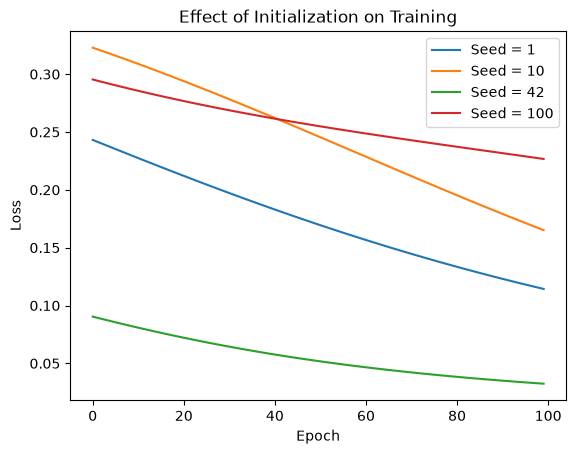

In [52]:
# plotting the findings
for seed in seeds:
    plt.plot(
        initialization_results[seed],
        label=f"Seed = {seed}"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Initialization on Training")
plt.legend()
plt.show()

In [53]:
# experiment 4: solving XOR problem
X = torch.tensor([
    [0.0, 0.0, 1.0, 1.0],
    [0.0, 1.0, 0.0, 1.0]
])

y = torch.tensor([
    [0.0, 1.0, 1.0, 0.0]
])

print(X.shape)
print(y.shape)

torch.Size([2, 4])
torch.Size([1, 4])


In [54]:
W1, b1, W2, b2 = reset_network()

z1 = W1 @ X + b1

print("W1 shape:", W1.shape)
print("X shape:", X.shape)
print("z1 shape:", z1.shape)

W1 shape: torch.Size([2, 2])
X shape: torch.Size([2, 4])
z1 shape: torch.Size([2, 4])


In [55]:
z1 = W1 @ X + b1
a1 = torch.sigmoid(z1)
z2 = W2 @ a1 + b2
y_hat = torch.sigmoid(z2)

print("z1:")
print(z1)
print("\na1:")
print(a1)
print("\ny_hat:")
print(y_hat)

z1:
tensor([[ 0.1000,  0.3000,  0.6000,  0.8000],
        [ 0.2000,  1.0000, -0.1000,  0.7000]], grad_fn=<AddBackward0>)

a1:
tensor([[0.5250, 0.5744, 0.6457, 0.6900],
        [0.5498, 0.7311, 0.4750, 0.6682]], grad_fn=<SigmoidBackward0>)

y_hat:
tensor([[0.5616, 0.5522, 0.5895, 0.5783]], grad_fn=<SigmoidBackward0>)


In [56]:
individual_losses = 0.5 * (y - y_hat) ** 2
print("individual losses: ")
print(individual_losses)
print(individual_losses.shape)

individual losses: 
tensor([[0.1577, 0.1002, 0.0842, 0.1672]], grad_fn=<MulBackward0>)
torch.Size([1, 4])


In [57]:
# loss.backward() needs one scalar, thus we'll take the mean

loss = individual_losses.mean()

# updating our training function
def train(W1, b1, W2, b2, X, y, optimizer, epochs):

    loss_history = []
    prediction_history = []

    for epoch in range(epochs):
        optimizer.zero_grad()
        z1 = W1 @ X + b1
        a1 = torch.sigmoid(z1)
        z2 = W2 @ a1 + b2
        y_hat = torch.sigmoid(z2)

        loss = (0.5 * (y - y_hat) ** 2).mean()
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())
        prediction_history.append(
            y_hat.detach().clone()
        )

    return loss_history, prediction_history

# .detach() → don't keep the computational graph attached
# .clone() → make an independent copy

In [58]:
# resetting out network
W1, b1, W2, b2 = reset_network()

optimizer = torch.optim.SGD([W1, b1, W2, b2],lr=0.5)

# increasing number of epochs from 100 to 500
loss_history, prediction_history = train(W1, b1, W2, b2,X, y,optimizer,epochs=5000)

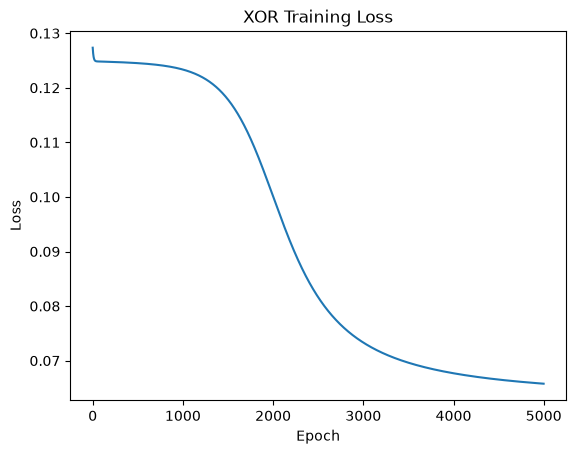

In [59]:
# plotting our findings
plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("XOR Training Loss")

plt.show()

In [60]:
print("Final predictions:")

for prediction in prediction_history[-1][0]:
    print(prediction.item())

Final predictions:
0.07406748086214066
0.4935830533504486
0.9227424263954163
0.508232057094574


In [61]:
print("Initial loss:", loss_history[0])
print("Final loss:", loss_history[-1])
print(loss_history[-10:])

Initial loss: 0.1273459643125534
Final loss: 0.06577657908201218
[0.06578786671161652, 0.06578658521175385, 0.06578533351421356, 0.06578407436609268, 0.065782830119133, 0.06578157842159271, 0.06578033417463303, 0.06577907502651215, 0.06577783823013306, 0.06577657908201218]


In [62]:
#.item(): takes a single-value tensor and gives us the ordinary Python number.
# .detach():Give me this tensor without its connection to the autograd graph- used for recording/inspection
# .clone(): makes an independent copy


In [63]:
# experiment 4: changing activation functions
# we'll compare sigmoid, tanh and ReLU

In [64]:
def train(W1, b1, W2, b2, X, y, optimizer, activation, epochs):

    loss_history = []
    prediction_history = []
    gradient_history = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        z1 = W1 @ X + b1
        a1 = activation(z1)
        z2 = W2 @ a1 + b2

        # using SIGMOID activation function
        y_hat = torch.sigmoid(z2)

        loss = (0.5 * (y - y_hat) ** 2).mean()

        loss.backward()
        
        gradient_history.append({
            "W1": torch.norm(W1.grad).item(),
            "W2": torch.norm(W2.grad).item()
        })

        optimizer.step()
        loss_history.append(loss.item())
        prediction_history.append(
            y_hat.detach().clone()
        )

    return loss_history, prediction_history, gradient_history

In [65]:
# resetting the network
W1, b1, W2, b2 = reset_network()

# making the optimiser
optimizer = torch.optim.SGD([W1, b1, W2, b2],lr=0.1)

loss_history, prediction_history, gradient_history = train(W1,b1,W2,b2,X,y,optimizer,activation=torch.sigmoid,epochs=5000)

In [66]:
# checking whether it works
print("Initial loss:", loss_history[0])
print("Final loss:", loss_history[-1])


Initial loss: 0.1273459643125534
Final loss: 0.12333907186985016


In [67]:
print("Final predictions:")
for prediction in prediction_history[-1][0]:
    print(prediction.item())

Final predictions:
0.4798770546913147
0.47508832812309265
0.5331023335456848
0.5127425193786621


In [68]:
print("Initial gradients:")
print(gradient_history[0])

print("\nFinal gradients:")
print(gradient_history[-1])

Initial gradients:
{'W1': 0.0018204919761046767, 'W2': 0.014898453839123249}

Final gradients:
{'W1': 0.002510274760425091, 'W2': 0.0013131217565387487}


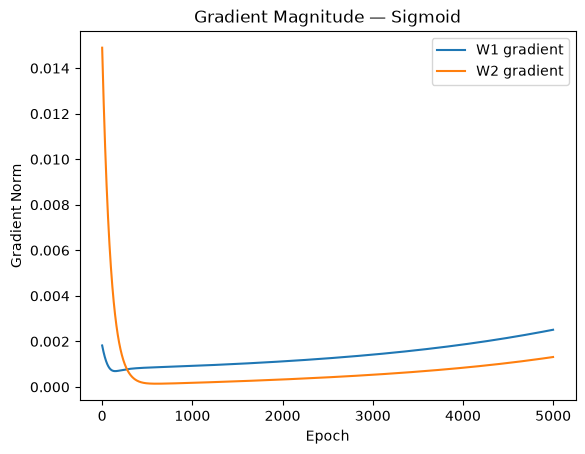

In [69]:
# plotting the findings
W1_gradients = [item["W1"]for item in gradient_history]
W2_gradients = [item["W2"]for item in gradient_history]
plt.plot(W1_gradients, label="W1 gradient")
plt.plot(W2_gradients, label="W2 gradient")

plt.xlabel("Epoch")
plt.ylabel("Gradient Norm")
plt.title("Gradient Magnitude — Sigmoid")
plt.legend()
plt.show()

In [70]:
def reset_network():

    W1 = torch.randn(2, 2) * 0.5
    b1 = torch.zeros(2, 1)

    W2 = torch.randn(1, 2) * 0.5
    b2 = torch.zeros(1, 1)

    W1.requires_grad_()
    b1.requires_grad_()
    W2.requires_grad_()
    b2.requires_grad_()

    return W1, b1, W2, b2

In [71]:
activations = {
    "Sigmoid": torch.sigmoid,
    "Tanh": torch.tanh,
    "ReLU": torch.relu
}

activation_results = {}

for name, activation in activations.items():
    # Same initialization for every experiment
    torch.manual_seed(42)

    W1, b1, W2, b2 = reset_network()
    # Same optimizer
    optimizer = torch.optim.SGD([W1, b1, W2, b2],lr=0.1)

    loss_history, prediction_history, gradient_history = train(W1,b1,W2,b2,X,y,optimizer,activation,epochs=5000)
    activation_results[name] = {
        "loss": loss_history,
        "predictions": prediction_history,
        "gradients": gradient_history
    }

In [72]:
# comparing final losses
for name in activation_results:
    final_loss = activation_results[name]["loss"][-1]
    print(f"{name}: Final Loss = {final_loss:.5f}")

Sigmoid: Final Loss = 0.12500
Tanh: Final Loss = 0.12500
ReLU: Final Loss = 0.08356


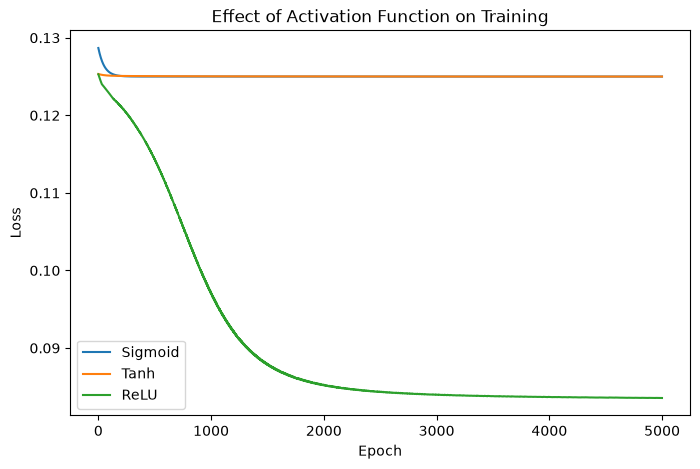

In [73]:
# plotting all three losses throughout the epochs
plt.figure(figsize=(8, 5))

for name in activation_results:
    plt.plot(activation_results[name]["loss"],label=name)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Activation Function on Training")
plt.legend()
plt.show()

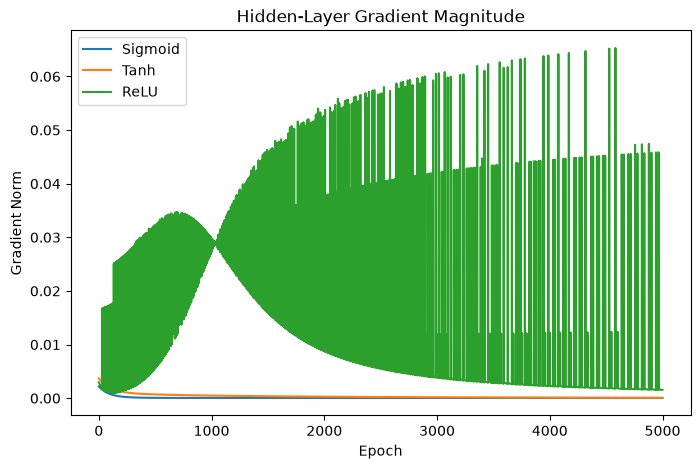

In [74]:
# similarly, plotting hidden-layer gradients throughout the epochs
plt.figure(figsize=(8, 5))

for name in activation_results:
    W1_gradients = [item["W1"] for item in activation_results[name]["gradients"]]
    plt.plot(W1_gradients,label=name)

plt.xlabel("Epoch")
plt.ylabel("Gradient Norm")
plt.title("Hidden-Layer Gradient Magnitude")
plt.legend()
plt.show()

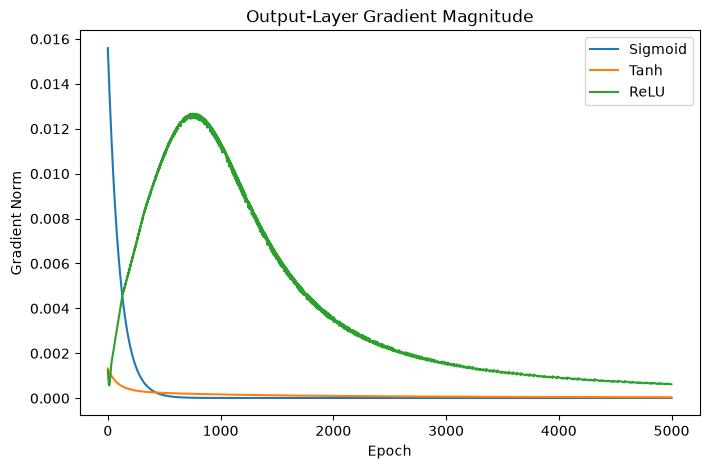

In [75]:
# comparing output layer gradients
plt.figure(figsize=(8, 5))

for name in activation_results:
    W2_gradients = [item["W2"] for item in activation_results[name]["gradients"]]
    plt.plot(W2_gradients,label=name)

plt.xlabel("Epoch")
plt.ylabel("Gradient Norm")
plt.title("Output-Layer Gradient Magnitude")
plt.legend()
plt.show()

In [76]:
# final predictions
for name in activation_results:
    final_predictions = activation_results[name]["predictions"][-1]
    print(f"\n{name}")
    for i in range(4):
        print(f"Input {X[:, i].tolist()} "
            f"Prediction: {final_predictions[0, i].item():.4f} "
            f"| Target: {y[0, i].item():.0f}"
        )


Sigmoid
Input [0.0, 0.0] Prediction: 0.5022 | Target: 0
Input [0.0, 1.0] Prediction: 0.5014 | Target: 1
Input [1.0, 0.0] Prediction: 0.4987 | Target: 1
Input [1.0, 1.0] Prediction: 0.4979 | Target: 0

Tanh
Input [0.0, 0.0] Prediction: 0.5014 | Target: 0
Input [0.0, 1.0] Prediction: 0.5010 | Target: 1
Input [1.0, 0.0] Prediction: 0.4992 | Target: 1
Input [1.0, 1.0] Prediction: 0.4988 | Target: 0

ReLU
Input [0.0, 0.0] Prediction: 0.6638 | Target: 0
Input [0.0, 1.0] Prediction: 0.6638 | Target: 1
Input [1.0, 0.0] Prediction: 0.6638 | Target: 1
Input [1.0, 1.0] Prediction: 0.0419 | Target: 0


In [77]:
# experiment 5: changing network depth
# we'll add more layers
# currently, it's input->hidden layer->output
# we'll try adding 3 hidden layers

In [78]:
# a generic deep network
def create_network(layer_sizes):
    weights=[]
    biases=[]
    for i in range(len(layer_sizes)-1):
        W=torch.randn(layer_sizes[i+1],layer_sizes[i])*0.5
        b=torch.zeros(layer_sizes[i+1],1)
        
        W.requires_grad_()
        b.requires_grad_()

        weights.append(W)
        biases.append(b)
    return weights,biases

def forward_deep(X, weights, biases, activation):
    a = X
    for i in range(len(weights) - 1):
        z = weights[i] @ a + biases[i]
        a = activation(z)

    # Output layer
    z = weights[-1] @ a + biases[-1]
    y_hat = torch.sigmoid(z)
    return y_hat

In [79]:
def train_deep(X,y,weights,biases,optimizer,activation,epochs):

    loss_history = []
    gradient_history = []

    for epoch in range(epochs):
        optimizer.zero_grad()
        y_hat = forward_deep(X,weights,biases,activation)
        loss = (0.5 * (y - y_hat) ** 2).mean()
        loss.backward()

        # Record gradient of every layer
        current_gradients = []
        for W in weights:
            current_gradients.append(torch.norm(W.grad).item())

        gradient_history.append(current_gradients)
        optimizer.step()
        loss_history.append(loss.item())

    return loss_history, gradient_history

In [80]:
import torch

In [81]:
layer_sizes=[2,2,2,1]
weights,biases=create_network(layer_sizes)

optimizer=torch.optim.SGD(weights+biases,lr=0.1)
loss_history,gradient_history=train_deep(X,y,weights,biases,optimizer,torch.sigmoid,epochs=3000)

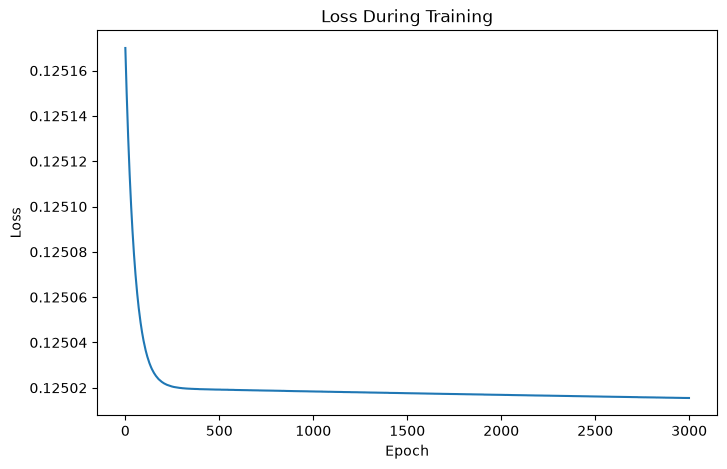

In [82]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss During Training")
plt.show()

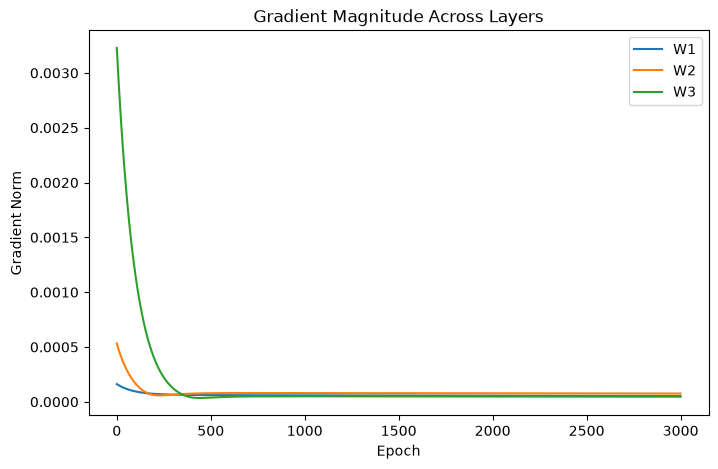

In [83]:
# above is the loss plotted
# now we will plot the gradient loss
plt.figure(figsize=(8, 5))

for i in range(len(gradient_history[0])):
    layer_gradients = [row[i] for row in gradient_history]
    plt.plot(layer_gradients,label=f"W{i+1}")

plt.xlabel("Epoch")
plt.ylabel("Gradient Norm")
plt.title("Gradient Magnitude Across Layers")
plt.legend()
plt.show()

In [84]:
# Experiment 6: how does optimizer affect backpropagation
optimizer_to_test=["SGD","Momentum","Adam"]
optimizer_results={}

for name in optimizer_to_test:
    torch.manual_seed(42)
    layer_sizes=[2,2,2,1]
    weights,biases=create_network(layer_sizes)
    parameters=weights+biases

    if name=="SGD":
        optimizer=torch.optim.SGD(parameters,lr=0.1)
    elif name=="Momentum":
        optimizer=torch.optim.SGD(parameters,lr=0.1,momentum=0.9)
    else:
        optimizer=torch.optim.Adam(parameters,lr=0.1)

    loss_history,gradient_history=train_deep(X,y,weights,biases,optimizer,torch.sigmoid,epochs=1000)
    optimizer_results[name]={
        "loss":loss_history,
        "gradients":gradient_history,
    }

# optimizer experiments are completed here

In [85]:
# plotting our findings

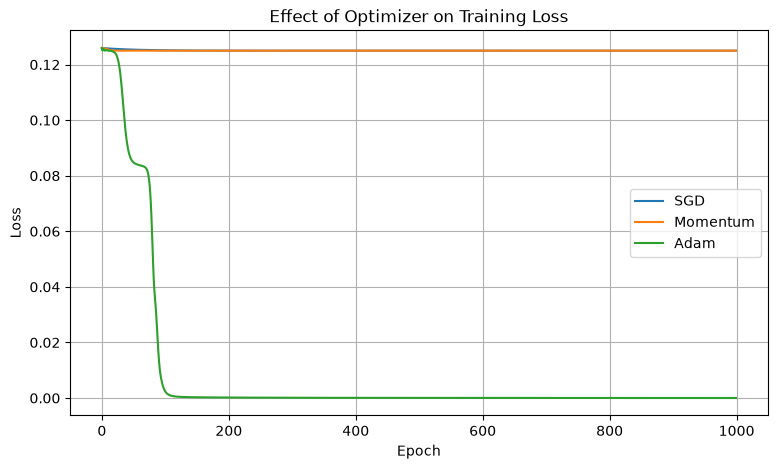

In [86]:
plt.figure(figsize=(9, 5))

for name in optimizer_to_test:
    plt.plot(optimizer_results[name]["loss"],label=name)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Optimizer on Training Loss")
plt.legend()
plt.grid(True)
plt.show()

In [87]:
# comparing final losses
for name in optimizer_to_test:
    final_loss = optimizer_results[name]["loss"][-1]
    print(f"{name}: final loss = {final_loss:.8f}")

SGD: final loss = 0.12500015
Momentum: final loss = 0.12500013
Adam: final loss = 0.00001622


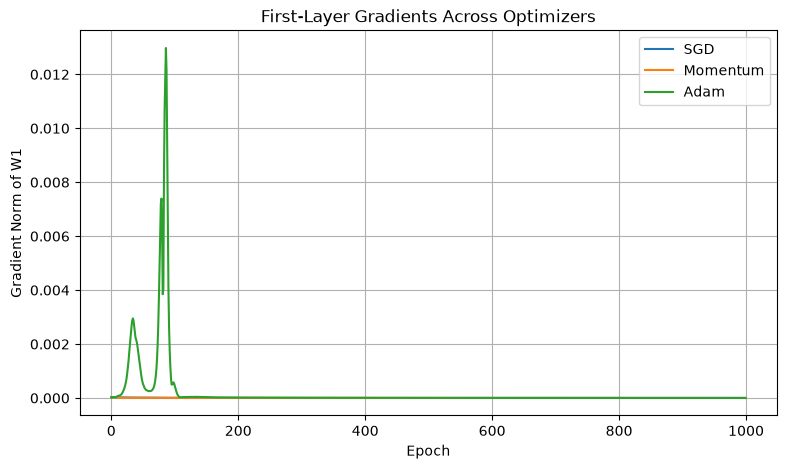

In [88]:
# plotting gradient norms using gradient history
plt.figure(figsize=(9, 5))

for name in optimizer_to_test:

    gradients = optimizer_results[name]["gradients"]
    first_layer_gradients = [row[0] for row in gradients]
    plt.plot(first_layer_gradients,label=name)

plt.xlabel("Epoch")
plt.ylabel("Gradient Norm of W1")
plt.title("First-Layer Gradients Across Optimizers")
plt.legend()
plt.grid(True)
plt.show()

In [89]:

def train_deep(X,y,weights,biases,optimizer,activation,epochs):
    loss_history = []
    gradient_history = []
    update_history = []

    for epoch in range(epochs):
        optimizer.zero_grad()
        
        y_hat = forward_deep(X, weights, biases, activation)
        loss = (0.5 * (y - y_hat) ** 2).mean()
        loss.backward()


        current_gradients = []
        for W in weights:
            current_gradients.append(torch.norm(W.grad).item())

        gradient_history.append(current_gradients)

        # Save copies of the weights before the update
        old_weights = [W.detach().clone() for W in weights]

        optimizer.step()
        current_updates = []

        for i in range(len(weights)):
            change = torch.norm(weights[i].detach() - old_weights[i]).item()
            current_updates.append(change)

        update_history.append(current_updates)
        loss_history.append(loss.item())

    return loss_history, gradient_history, update_history


In [90]:
# running the experiment
torch.manual_seed(42)

layer_sizes = [2, 2, 2, 1]
weights, biases = create_network(layer_sizes)
optimizer = torch.optim.SGD(weights + biases,lr=0.1)

loss_history, gradient_history, update_history = train_deep(X,y,weights,biases,optimizer,torch.sigmoid,epochs=1000)

print("Final loss:", loss_history[-1])

Final loss: 0.12500014901161194


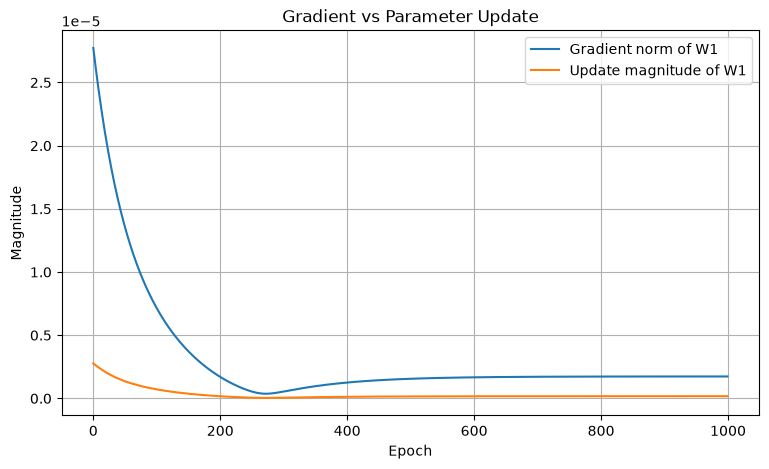

In [91]:
# gradient vs parameter update
plt.figure(figsize=(9, 5))

plt.plot([row[0] for row in gradient_history],label="Gradient norm of W1")
plt.plot([row[0] for row in update_history],label="Update magnitude of W1")

plt.xlabel("Epoch")
plt.ylabel("Magnitude")
plt.title("Gradient vs Parameter Update")
plt.legend()
plt.grid(True)
plt.show()

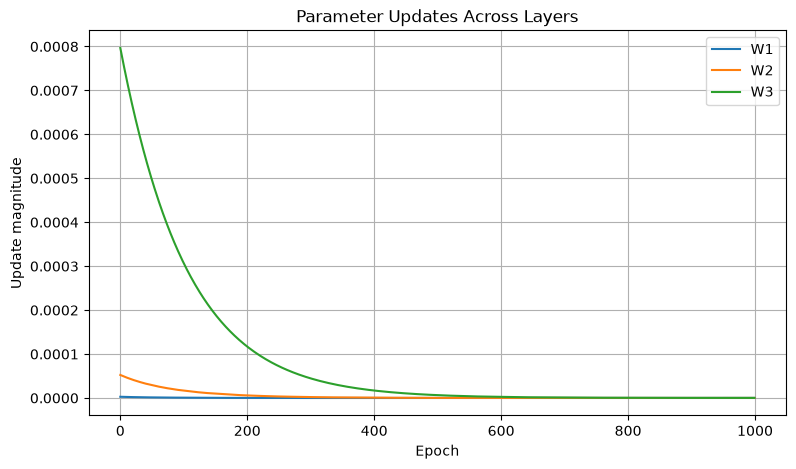

In [92]:
# update magnitudes throughout the layers
plt.figure(figsize=(9, 5))

for i in range(len(weights)):
    plt.plot(
        [row[i] for row in update_history],
        label=f"W{i+1}"
    )

plt.xlabel("Epoch")
plt.ylabel("Update magnitude")
plt.title("Parameter Updates Across Layers")
plt.legend()
plt.grid(True)
plt.show()

In [93]:
# Experiment 8: Gradient checking
# creating a fresh network
torch.manual_seed(42)
layer_sizes=[2,2,2,1]
weights,biases=create_network(layer_sizes)

In [96]:
y_hat=forward_deep(X,weights,biases,torch.sigmoid)
loss=(0.5*(y-y_hat)**2).mean()
loss.backward()
auto_gradient=weights[0].grad[0,0].item()
# weight[0] : selects the 1st layer of weight matrix
# .grad() contanins the gradients calcualted by .backward()
# [0,0] : 1st row,1st column
print("Loss : ",loss)
print("Gradient from pytorch : ",auto_gradient)

Loss :  tensor(0.1260, grad_fn=<MeanBackward0>)
Gradient from pytorch :  4.991896275896579e-06


In [97]:
epsilon = 1e-5
# saving the original weight
original_weight = weights[0][0, 0].item()

# Calculate loss when weight is slightly increased
with torch.no_grad():
    weights[0][0, 0] = original_weight + epsilon
    y_hat_plus = forward_deep(X, weights, biases, torch.sigmoid)
    loss_plus = (0.5 * (y - y_hat_plus) ** 2).mean().item()

# Calculate loss when weight is slightly decreased
with torch.no_grad():
    weights[0][0, 0] = original_weight - epsilon
    y_hat_minus = forward_deep(X, weights, biases, torch.sigmoid)
    loss_minus = (0.5 * (y - y_hat_minus) ** 2).mean().item()

# Restore the original weight
with torch.no_grad():
    weights[0][0, 0] = original_weight

# Numerical gradient using central difference scheme
numerical_gradient = (loss_plus - loss_minus) / (2 * epsilon)
print("Gradient from PyTorch:", auto_gradient)
print("Numerical gradient:", numerical_gradient)

Gradient from PyTorch: 4.991896275896579e-06
Numerical gradient: 0.0


In [98]:
difference = abs(auto_gradient - numerical_gradient)
print("Absolute difference:", difference)

if difference < 1e-4:
    print("Gradient check passed!")
else:
    print("Gradient check needs investigation.")

Absolute difference: 4.991896275896579e-06
Gradient check passed!
